<a href="https://colab.research.google.com/github/carissanabilah/Implementasi-Kode-Deep-Learning/blob/main/Studi-Kasus-1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ANALISIS RISIKO GAGAL BAYAR KARTU KREDIT

Mengunduh dataset asli dari UCI...

Ukuran dataset: (30000, 24)

Lima data pertama:
       X1  X2  X3  X4  X5  X6  X7  X8  X9  X10  ...    X15    X16    X17  \
0   20000   2   2   1  24   2   2  -1  -1   -2  ...      0      0      0   
1  120000   2   2   2  26  -1   2   0   0    0  ...   3272   3455   3261   
2   90000   2   2   2  34   0   0   0   0    0  ...  14331  14948  15549   
3   50000   2   2   1  37   0   0   0   0    0  ...  28314  28959  29547   
4   50000   1   2   1  57  -1   0  -1   0    0  ...  20940  19146  19131   

    X18    X19    X20   X21   X22   X23  default_next_month  
0     0    689      0     0     0     0                   1  
1     0   1000   1000  1000     0  2000                   1  
2  1518   1500   1000  1000  1000  5000                   0  
3  2000   2019   1200  1100  1069  1000                   0  
4  2000  36681  10000  9000   689   679                   0  

[5 rows x 24 columns]

Informasi dataset:
<c

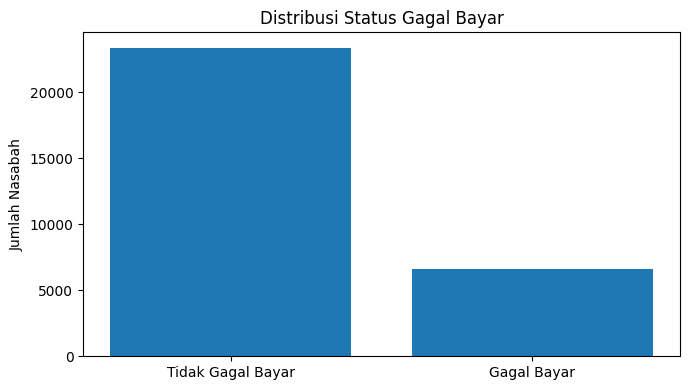


Jumlah data training: 24000
Jumlah data testing : 6000

MODEL: Logistic Regression
                   precision    recall  f1-score   support

Tidak Gagal Bayar       0.87      0.70      0.77      4673
      Gagal Bayar       0.37      0.62      0.46      1327

         accuracy                           0.68      6000
        macro avg       0.62      0.66      0.62      6000
     weighted avg       0.76      0.68      0.70      6000



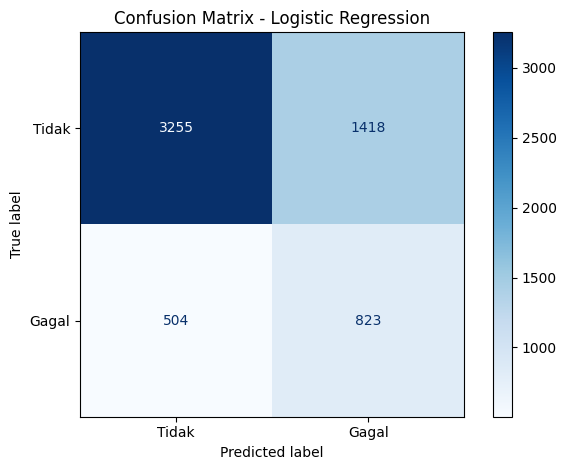


MODEL: Decision Tree
                   precision    recall  f1-score   support

Tidak Gagal Bayar       0.88      0.77      0.82      4673
      Gagal Bayar       0.43      0.61      0.51      1327

         accuracy                           0.73      6000
        macro avg       0.65      0.69      0.66      6000
     weighted avg       0.78      0.73      0.75      6000



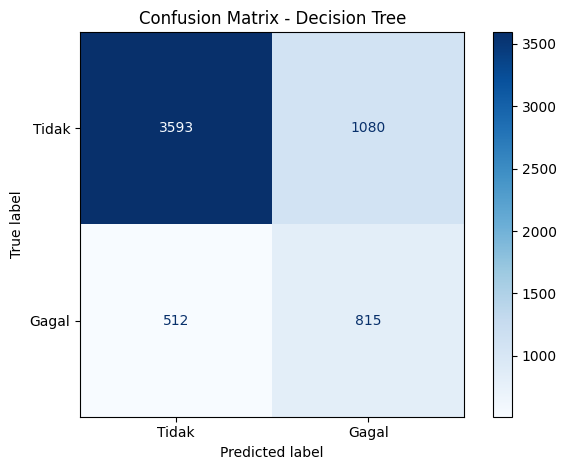


MODEL: Random Forest
                   precision    recall  f1-score   support

Tidak Gagal Bayar       0.87      0.88      0.87      4673
      Gagal Bayar       0.55      0.52      0.53      1327

         accuracy                           0.80      6000
        macro avg       0.71      0.70      0.70      6000
     weighted avg       0.80      0.80      0.80      6000



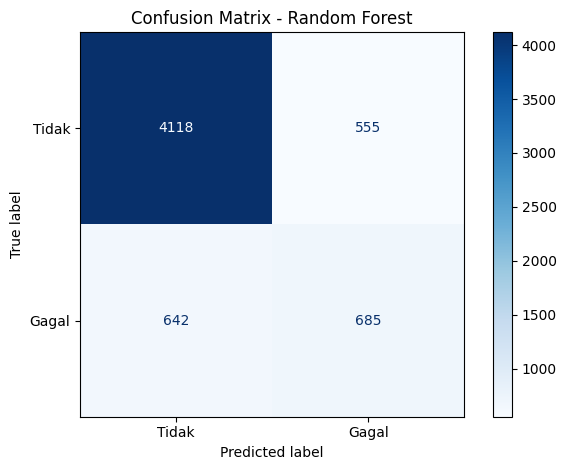


HASIL PERBANDINGAN MODEL:
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
      Random Forest    0.8005     0.5524  0.5162    0.5337   0.7685
      Decision Tree    0.7347     0.4301  0.6142    0.5059   0.7504
Logistic Regression    0.6797     0.3672  0.6202    0.4613   0.7081


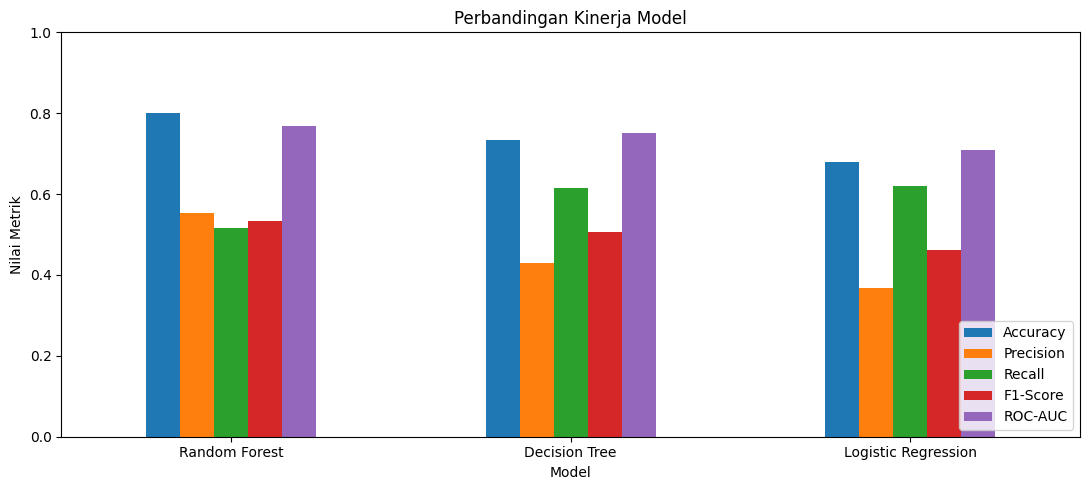


Model terbaik berdasarkan F1-Score: Random Forest

10 FITUR PALING BERPENGARUH:
Fitur  Importance
   X6      0.1388
   X1      0.0561
   X7      0.0558
  X12      0.0554
  X18      0.0514
  X19      0.0512
  X13      0.0494
  X20      0.0483
   X5      0.0453
  X14      0.0452


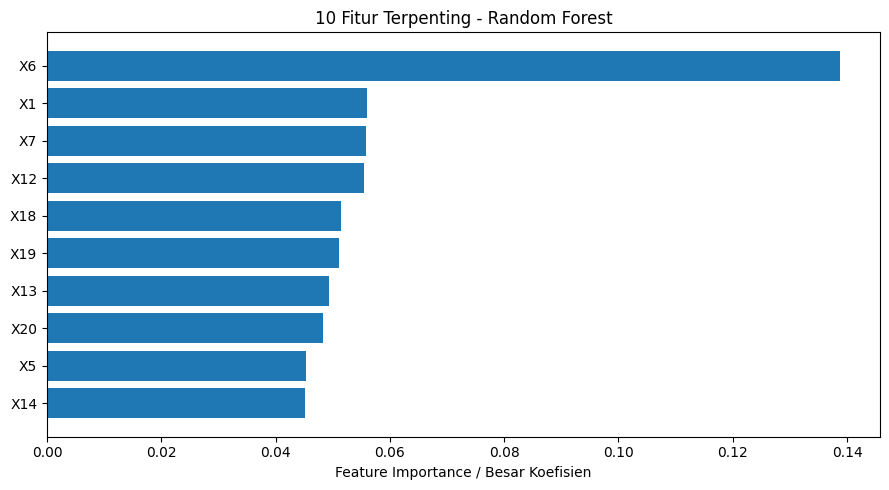


DISTRIBUSI KATEGORI RISIKO:
Kategori_Risiko
Rendah    4383
Sedang     982
Tinggi     635
Name: count, dtype: int64

CONTOH HASIL PREDIKSI PADA DATA TEST:
       Aktual  Prediksi  Probabilitas_Risiko Kategori_Risiko                        Rekomendasi
6907        0         0             0.228662          Rendah                   Pemantauan rutin
24575       0         0             0.285555          Rendah                   Pemantauan rutin
26766       0         0             0.286479          Rendah                   Pemantauan rutin
2156        1         0             0.236647          Rendah                   Pemantauan rutin
3179        0         0             0.029863          Rendah                   Pemantauan rutin
29382       0         1             0.549514          Sedang  Lakukan pemantauan dan verifikasi
24454       0         0             0.152742          Rendah                   Pemantauan rutin
23886       0         0             0.017103          Rendah                 

In [2]:


!pip -q install ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

# ============================================================
# 1. BUSINESS UNDERSTANDING
# ============================================================

print("=" * 65)
print("ANALISIS RISIKO GAGAL BAYAR KARTU KREDIT")
print("=" * 65)



# ============================================================
# 2. DATA UNDERSTANDING - DATASET UCI
# ============================================================

print("\nMengunduh dataset asli dari UCI...")

dataset = fetch_ucirepo(id=350)

X = dataset.data.features.copy()
y = dataset.data.targets.iloc[:, 0].copy()

# Menghapus kolom ID jika tersedia
X = X.drop(columns=["ID"], errors="ignore")

# Target: 0 = Tidak gagal bayar, 1 = Gagal bayar
y = pd.to_numeric(y, errors="raise").astype(int)
assert set(y.unique()).issubset({0, 1})

df = X.copy()
df["default_next_month"] = y

print("\nUkuran dataset:", df.shape)
print("\nLima data pertama:")
print(df.head())

print("\nInformasi dataset:")
df.info()

print("\nStatistik deskriptif:")
print(df.describe().round(2))

print("\nJumlah missing values:")
print(df.isnull().sum())

print("\nJumlah baris duplikat:", df.duplicated().sum())

# ============================================================
# 3. DESCRIPTIVE ANALYTICS
# ============================================================

distribusi = y.value_counts().sort_index()

print("\nDistribusi target:")
print(distribusi)

print("\nPersentase target:")
print((y.value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(7, 4))
plt.bar(
    ["Tidak Gagal Bayar", "Gagal Bayar"],
    [distribusi.get(0, 0), distribusi.get(1, 0)]
)
plt.title("Distribusi Status Gagal Bayar")
plt.ylabel("Jumlah Nasabah")
plt.tight_layout()
plt.show()

# Analisis berdasarkan status pembayaran terakhir
if "PAY_0" in df.columns:
    ringkasan = (
        df.groupby("PAY_0")["default_next_month"]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "jumlah_nasabah",
            "mean": "proporsi_gagal_bayar"
        })
    )

    print("\nRisiko berdasarkan status pembayaran terakhir:")
    print(ringkasan.round(3))

    plt.figure(figsize=(8, 4))
    plt.bar(
        ringkasan.index.astype(str),
        ringkasan["proporsi_gagal_bayar"] * 100
    )
    plt.title("Proporsi Gagal Bayar Menurut Status Pembayaran")
    plt.xlabel("Kode Status Pembayaran PAY_0")
    plt.ylabel("Gagal Bayar (%)")
    plt.tight_layout()
    plt.show()

# ============================================================
# 4. DATA PREPARATION
# ============================================================


X = X.apply(pd.to_numeric, errors="coerce")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nJumlah data training:", len(X_train))
print("Jumlah data testing :", len(X_test))

# ============================================================
# 5. MODELING
# ============================================================

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=8,
            min_samples_leaf=20,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=150,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

hasil = []
prediksi_model = {}

for nama, model in models.items():

    print("\n" + "=" * 55)
    print("MODEL:", nama)
    print("=" * 55)

    model.fit(X_train, y_train)

    prediksi = model.predict(X_test)
    probabilitas = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, prediksi)
    precision = precision_score(
        y_test, prediksi, zero_division=0
    )
    recall = recall_score(
        y_test, prediksi, zero_division=0
    )
    f1 = f1_score(
        y_test, prediksi, zero_division=0
    )
    auc = roc_auc_score(y_test, probabilitas)

    hasil.append({
        "Model": nama,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

    prediksi_model[nama] = {
        "prediksi": prediksi,
        "probabilitas": probabilitas,
        "pipeline": model
    }

    print(classification_report(
        y_test,
        prediksi,
        target_names=[
            "Tidak Gagal Bayar",
            "Gagal Bayar"
        ],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        prediksi,
        display_labels=["Tidak", "Gagal"],
        cmap="Blues"
    )
    plt.title("Confusion Matrix - " + nama)
    plt.tight_layout()
    plt.show()

# ============================================================
# 6. EVALUATION
# ============================================================

hasil_df = pd.DataFrame(hasil)

hasil_df = hasil_df.sort_values(
    by=["F1-Score", "Recall"],
    ascending=False
).reset_index(drop=True)

print("\nHASIL PERBANDINGAN MODEL:")
print(hasil_df.round(4).to_string(index=False))

hasil_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
].plot(kind="bar", figsize=(11, 5))

plt.title("Perbandingan Kinerja Model")
plt.ylabel("Nilai Metrik")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

model_terbaik = hasil_df.iloc[0]["Model"]
best = prediksi_model[model_terbaik]

print("\nModel terbaik berdasarkan F1-Score:", model_terbaik)

# ============================================================
# 7. ANALISIS FEATURE IMPORTANCE
# ============================================================

pipeline_terbaik = best["pipeline"]
estimator = pipeline_terbaik.named_steps["model"]

if hasattr(estimator, "feature_importances_"):
    importance = estimator.feature_importances_
else:

    importance = np.abs(estimator.coef_[0])

fitur_penting = pd.DataFrame({
    "Fitur": X_train.columns,
    "Importance": importance
}).sort_values("Importance", ascending=False)

print("\n10 FITUR PALING BERPENGARUH:")
print(fitur_penting.head(10).round(4).to_string(index=False))

top10 = fitur_penting.head(10).iloc[::-1]

plt.figure(figsize=(9, 5))
plt.barh(top10["Fitur"], top10["Importance"])
plt.title("10 Fitur Terpenting - " + model_terbaik)
plt.xlabel("Feature Importance / Besar Koefisien")
plt.tight_layout()
plt.show()

# ============================================================
# 8. PRESCRIPTIVE ANALYTICS SEDERHANA
# ============================================================


probabilitas = best["probabilitas"]

def kategori_risiko(p):
    if p >= 0.70:
        return "Tinggi"
    elif p >= 0.40:
        return "Sedang"
    return "Rendah"

def rekomendasi(kategori):
    if kategori == "Tinggi":
        return "Prioritaskan pemeriksaan manual"
    elif kategori == "Sedang":
        return "Lakukan pemantauan dan verifikasi"
    return "Pemantauan rutin"

hasil_prediksi = X_test.copy()
hasil_prediksi["Aktual"] = y_test.to_numpy()
hasil_prediksi["Prediksi"] = best["prediksi"]
hasil_prediksi["Probabilitas_Risiko"] = probabilitas

hasil_prediksi["Kategori_Risiko"] = (
    hasil_prediksi["Probabilitas_Risiko"]
    .apply(kategori_risiko)
)

hasil_prediksi["Rekomendasi"] = (
    hasil_prediksi["Kategori_Risiko"]
    .apply(rekomendasi)
)

print("\nDISTRIBUSI KATEGORI RISIKO:")
print(hasil_prediksi["Kategori_Risiko"].value_counts())

print("\nCONTOH HASIL PREDIKSI PADA DATA TEST:")
print(
    hasil_prediksi[
        [
            "Aktual",
            "Prediksi",
            "Probabilitas_Risiko",
            "Kategori_Risiko",
            "Rekomendasi"
        ]
    ].head(10).to_string()
)

# ============================================================
# 9. DEPLOYMENT - SIMPAN CSV
# ============================================================

hasil_df.to_csv(
    "perbandingan_model.csv",
    index=False
)

hasil_prediksi.to_csv(
    "hasil_prediksi_risiko.csv",
    index=False
)

fitur_penting.to_csv(
    "feature_importance.csv",
    index=False
)

print("\nFILE BERHASIL DISIMPAN:")
print("1. perbandingan_model.csv")
print("2. hasil_prediksi_risiko.csv")
print("3. feature_importance.csv")

print("\nKESIMPULAN OTOMATIS:")
print("Model terbaik berdasarkan F1-Score:", model_terbaik)
print(
    "F1-Score:",
    round(hasil_df.iloc[0]["F1-Score"], 4)
)
print(
    "Recall:",
    round(hasil_df.iloc[0]["Recall"], 4)
)


print("\nPROGRAM SELESAI.")
